### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_AMXPEBRKGTEC


### Main

In [3]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import ttest_ind

In [4]:
from matplotlib import font_manager
import matplotlib as mpl

font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
ogl_rf_size = np.array([16., 44., 20., 32., 32., 36., 20., 40., 40., 16., 40.,  8., 40.,
       36., 28., 20., 24., 48., 20., 16., 36., 40., 20., 36., 28., 40.,
       32., 40., 20., 36., 64., 48., 44., 20., 32., 16., 52., 52., 12.,
       40., 36., 44., 36., 68., 24., 44., 20., 48., 64., 32., 36., 36.,
       44., 40., 40., 28., 40., 40., 40., 40., 32., 40., 16., 36., 36.,
       40., 28., 40., 64., 28., 48., 24., 40., 32., 40., 20., 32., 20.,
       40., 36., 36., 40., 32., 52., 36., 44., 40., 24., 24., 36., 32.,
       36., 32., 40., 40., 28., 48., 12., 44., 40., 40., 28., 48., 48.,
       40., 32., 44., 44., 44., 48., 44., 16., 44., 44., 24., 36., 32.,
       36., 28., 32., 28., 32., 52., 44., 24., 16., 40., 44., 40., 16.,
       16., 24., 36., 32., 24., 36., 32., 44., 20., 20., 36., 36., 20.,
       24.,  8., 32., 40., 28., 28., 40., 44., 24., 16., 24., 24., 16.,
       16., 44., 24., 36., 32., 32., 20., 44., 28., 28., 16., 44., 44.,
       32., 24., 32., 36., 36., 32., 36., 32., 36., 36., 28., 20., 24.,
       20., 32., 16., 28., 12., 32., 32., 16., 28., 24., 28., 36., 24.,
       32., 32., 20., 20., 24., 32., 40., 32., 36., 32., 36., 16., 36.,
       32., 28., 28., 28., 48., 40., 52., 40., 24., 32., 28., 28., 52.,
       24., 32., 44., 40., 40., 32., 40., 36., 40., 44., 36., 36., 24.,
       16., 40., 28., 20., 40., 24., 40., 28., 36., 36., 36., 32., 32.,
       32., 24., 32., 32., 32., 28., 40., 32., 40., 24., 28., 28., 44.,
       20., 28., 36., 44., 40., 44., 28., 40., 44., 24., 20., 40., 24.,
       32., 40., 28., 32., 32., 24., 20., 16., 28., 36., 28., 32., 32.,
       32., 28., 28., 28., 32., 40., 40., 28., 36., 24., 32., 32., 60.,
       72., 60., 68., 56., 36., 36., 20., 44., 60., 32., 40., 64., 36.,
       20., 64., 24., 16., 48., 20., 16., 52., 20., 36., 32., 32., 20.,
       20., 20., 28., 16., 20., 80., 40., 40., 12., 20., 12., 12., 16.,
       16., 32., 28., 20., 24., 24., 60., 20., 24., 32., 28., 40., 32.,
       28., 32., 20., 20., 60., 52., 24., 24., 52., 56., 28., 28., 20.,
       40., 28., 20., 24., 24., 28., 24., 28., 48., 36., 72., 36., 44.,
       40., 56., 60., 40., 40., 52., 40., 28., 68., 32., 40., 32., 64.,
       56., 44., 28., 36.])

igl_rf_size = np.array([20., 36., 48., 44., 60., 36., 40., 20., 60., 40., 40., 48., 20.,
       56., 12., 68., 36., 44., 28., 44., 40., 52., 32., 48., 20., 28.,
       52., 48., 52., 72., 44., 48., 40., 36., 20., 24., 36., 68., 32.,
       36., 48., 44., 44., 44., 40., 24., 16., 64., 48., 24., 52., 32.,
       20., 52., 44., 60., 28., 60., 44., 24., 40., 16., 28., 32., 56.,
       32., 28., 52., 40., 44., 60., 32., 48., 20., 48., 52., 60., 60.,
       36., 40., 56., 52., 56., 40., 40., 52., 36., 28., 84., 80., 48.,
       40., 48., 32., 56., 48., 16., 20., 36., 60., 32., 48., 60., 16.,
       44., 36., 52., 52., 40., 48., 40., 16., 44., 36., 52., 52., 40.,
       60., 56., 40., 56., 60., 32., 36., 36., 48., 48., 56., 56., 48.,
       52., 40., 56., 36., 28., 44., 52., 60., 72., 64., 56., 44., 40.,
       28., 48., 32., 36., 24., 32., 20., 44., 48., 72., 48., 52., 20.,
       40., 64., 52., 64., 20., 52., 64., 64., 48., 60., 24., 48., 48.,
       52., 32., 72., 64., 56., 32., 64., 48., 52., 44., 52., 40., 60.,
       64., 40., 36., 56., 52., 64., 64., 32., 52., 28., 24., 60., 24.,
       56., 64., 24., 56., 64., 52., 60., 72., 68., 40., 44., 60., 32.,
       20., 48., 52., 44., 36., 48., 28., 52., 32., 40., 60., 52., 60.,
       48., 32., 44., 40., 44., 48., 48., 56., 56., 24., 60., 44., 12.,
       36., 36., 32., 24., 20., 32., 28., 52., 52., 48., 40., 48., 44.,
       28., 36., 40., 36., 28., 48., 20., 44., 44., 48., 56., 20., 64.,
       32., 32., 20., 56., 68., 72., 56., 56., 48., 48., 28., 56., 44.,
       56., 64., 72., 44., 60., 44., 64., 52., 36., 36., 40., 28., 48.,
       80., 48., 44., 40., 64., 72.,  8., 64., 64., 60., 36.])

In [6]:
print(ogl_rf_size.size, igl_rf_size.size)

394 297


In [7]:
print(np.median(ogl_rf_size), np.median(igl_rf_size))
print(np.mean(ogl_rf_size), np.mean(igl_rf_size))
print(np.std(ogl_rf_size), np.std(igl_rf_size))

32.0 44.0
33.5736040609137 44.63299663299663
11.836488096666239 14.3821106416411


In [8]:
t_stat, p_val = ttest_ind(ogl_rf_size, igl_rf_size, equal_var=False)  # Welch's t-test

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:}")

T-statistic: -10.766
P-value: 1.0377929717553696e-24


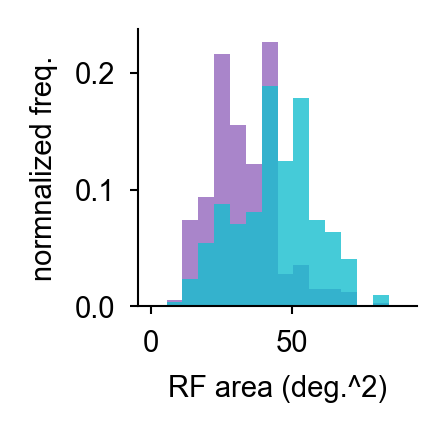

In [9]:
fig = plt.figure(figsize=(1.2,1.2), dpi=300)
gs = fig.add_gridspec(1,1)
ax = fig.add_subplot(gs[0, 0])

h_ogl, bin_edges = np.histogram(ogl_rf_size, range=[0, 90], bins=16, density=False)
h_igl, bin_edges = np.histogram(igl_rf_size, range=[0, 90], bins=16, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

h_ogl = h_ogl / h_ogl.sum()
h_igl = h_igl / h_igl.sum()

ax.bar(bin_centers, h_ogl, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.8, label="OGL", color="#9467bd")
ax.bar(bin_centers, h_igl, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.8, label="IGL", color="#17becf")

ax.set_xlabel("RF area (deg.^2)")
ax.set_ylabel("normnalized freq.")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.savefig(os.path.join(tmpdir, "RF_size_OGL_IGL.pdf"), bbox_inches='tight')
plt.show()

In [10]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field/"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field/
cp -r /flash/ReiterU/tmp/tomo_RSQVMQIOKPTH/* /bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field/
